# Blood Cell Detective
## 01 — Dataset exploration and preparation

This notebook is the starting point of the Blood Cell Detective project. Before training a classifier, I want to understand the dataset, check the image files, look for duplicates and inspect the distribution of the cell types.

The dataset contains images of peripheral blood cells across eight classes. The aim of this project is to build and compare image-classification models for educational purposes — **not** to provide clinical diagnoses.

**What this notebook covers**
1. Build an inventory of the images.
2. Inspect image dimensions, formats and visual examples.
3. Check file integrity and identify exact duplicates.
4. Create a cleaned inventory and examine class imbalance.
5. Create stratified training, validation and test splits.

The processed CSV files created here are used by the following notebooks.

## 1. Set up the notebook

The dataset is expected at `../data/raw/PBC_dataset_normal_DIB/`, with one subfolder per cell class. The paths are relative to this notebook's location in the project.

In [ ]:
from collections import Counter, defaultdict
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

DATA_DIR = Path("../data/raw/PBC_dataset_normal_DIB")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR.resolve()}. "
        "Check that the dataset has been downloaded and extracted."
    )

print("Dataset folder:", DATA_DIR.resolve())

Dataset exists: True


## 2. Build an image inventory

I create one row per image, recording its filename, class label and file path. Keeping this information in a DataFrame makes it easier to inspect the dataset and later create reproducible splits.

Hidden macOS metadata files are ignored because they are not image samples.

In [ ]:
records = []

for class_folder in sorted(DATA_DIR.iterdir()):
    if not class_folder.is_dir():
        continue

    for image_path in sorted(class_folder.glob("*.jpg")):
        if image_path.name.startswith("."):
            continue

        records.append({
            "filename": image_path.name,
            "class": class_folder.name,
            "path": str(image_path)
        })

df = pd.DataFrame(records)

print(f"Total image files in inventory: {len(df):,}")
print("\nImages per class:")
print(df["class"].value_counts().sort_index())

Total valid image files: 17092

Images per class:
class
neutrophil      3329
eosinophil      3117
ig              2895
platelet        2348
erythroblast    1551
monocyte        1420
basophil        1218
lymphocyte      1214
Name: count, dtype: int64


## 3. Explore image dimensions and appearance

Image models generally expect inputs with consistent dimensions. First, I check the dimensions present in the original files. I also display one randomly selected example from each class to get a visual sense of the differences between cell types.

The sample images are useful for an initial inspection, but they are not a substitute for expert annotation or clinical assessment.

In [ ]:
dimensions = []

for image_path in df["path"]:
    with Image.open(image_path) as img:
        dimensions.append(img.size)

dimension_df = pd.DataFrame(dimensions, columns=["width", "height"])

print("Image dimensions (width, height):")
print(dimension_df.value_counts())
print("\nMinimum dimensions:")
print(dimension_df.min())
print("\nMaximum dimensions:")
print(dimension_df.max())

Unique image dimensions:
width  height
360    363       16639
366    369         250
360    360         198
       361           2
361    360           1
359    360           1
362    360           1
Name: count, dtype: int64

Minimum dimensions:
width     359
height    360
dtype: int64

Maximum dimensions:
width     366
height    369
dtype: int64


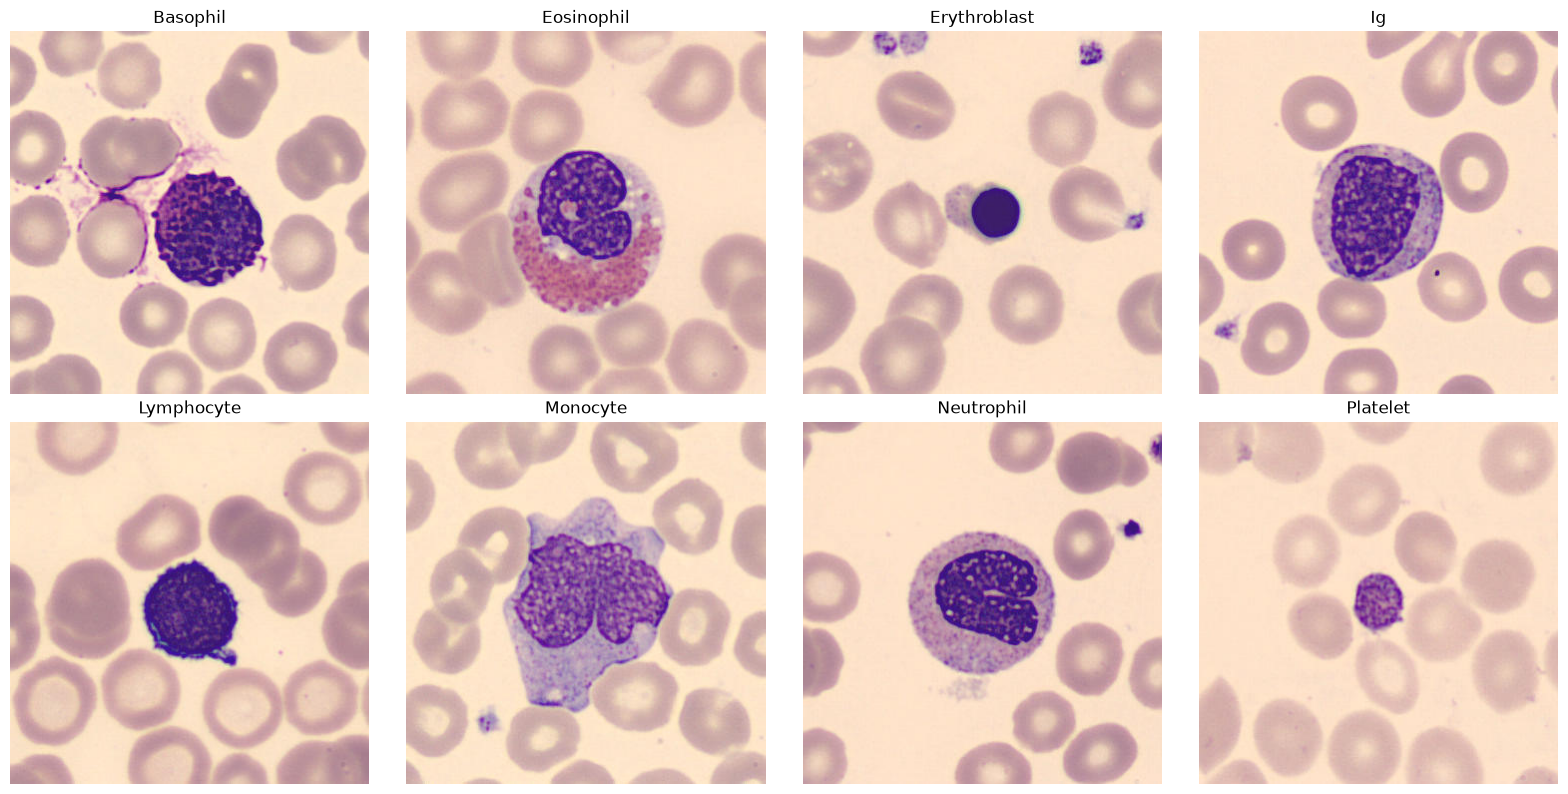

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
classes = sorted(df["class"].unique())

for ax, cell_class in zip(axes.flat, classes):
    sample = df[df["class"] == cell_class].sample(
        n=1, random_state=42
    ).iloc[0]

    with Image.open(sample["path"]) as image:
        ax.imshow(image)

    ax.set_title(cell_class.capitalize())
    ax.axis("off")

plt.suptitle("One example image from each class", y=1.02)
plt.tight_layout()
plt.show()

### Initial visual observations

The examples show some of the morphological features that distinguish the classes:

- **Basophils:** dark granules can partly obscure the nucleus.
- **Eosinophils:** often have prominent granules and a bilobed nucleus.
- **Neutrophils:** commonly have a segmented nucleus.
- **Lymphocytes:** typically have a large, dense nucleus with a relatively thin rim of cytoplasm.
- **Monocytes:** often have abundant cytoplasm and an irregularly shaped nucleus.
- **Platelets:** are much smaller than the surrounding blood cells.

These are broad visual descriptions, not rules that identify every individual cell. The classifier will learn patterns from the labelled examples.

## 4. Check image integrity and encoding

Before preprocessing, I check whether the files can be opened and verified. I then inspect their color mode and format.

For this dataset, RGB images have three color channels. Pixel values are represented as 8-bit unsigned integers (`uint8`), normally ranging from 0 to 255. The image array shape is ordered as **height × width × channels**.

In [ ]:
corrupted_images = []

for image_path in df["path"]:
    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception:
        corrupted_images.append(image_path)

print("Corrupted images:", len(corrupted_images))

Corrupted images: 0


In [ ]:
image_modes = Counter()

for image_path in df["path"]:
    with Image.open(image_path) as img:
        image_modes[img.mode] += 1

print("Image color modes:")
print(image_modes)

Image color modes:
Counter({'RGB': 17092})


In [ ]:
sample_path = df.iloc[0]["path"]

with Image.open(sample_path) as sample_image:
    image_array = np.array(sample_image)

    print("Image size (width, height):", sample_image.size)
    print("Image mode:", sample_image.mode)
    print("Image format:", sample_image.format)

print("Array shape (height, width, channels):", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

Image size: (360, 363)
Image mode: RGB
Image format: JPEG
Array shape: (363, 360, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In the sample image, a shape of `(363, 360, 3)` means 363 pixels in height, 360 in width and 3 color channels. `uint8` means each channel value is stored as an unsigned 8-bit integer. Later, the preprocessing notebook converts pixel values to floating point and scales them to the range 0–1.

In [ ]:
mode_records = []

for image_path in df["path"]:
    with Image.open(image_path) as img:
        mode_records.append({
            "filename": image_path,
            "mode": img.mode,
            "format": img.format
        })

mode_df = pd.DataFrame(mode_records)

print("Color mode distribution:")
print(mode_df["mode"].value_counts())
print("\nImages that are not RGB:")
print(mode_df[mode_df["mode"] != "RGB"])

Color mode distribution:
mode
RGB    17092
Name: count, dtype: int64

Non-RGB images:
Empty DataFrame
Columns: [filename, mode, format]
Index: []


## 5. Find exact duplicate images

Duplicate images can cause data leakage if copies end up in different splits. For example, a model could be evaluated on an image that is effectively identical to one it saw during training, making the evaluation look better than it really is.

I use a SHA-256 hash of each file's bytes to identify **exact file duplicates**. This method will not detect visually similar images that have been resized, recompressed or otherwise changed.

In [ ]:
image_hashes = defaultdict(list)

for image_path in df["path"]:
    with open(image_path, "rb") as file:
        image_hash = hashlib.sha256(file.read()).hexdigest()

    image_hashes[image_hash].append(image_path)

duplicates = {
    image_hash: paths
    for image_hash, paths in image_hashes.items()
    if len(paths) > 1
}

print("Exact duplicate groups:", len(duplicates))
print(
    "Files involved in exact duplicates:",
    sum(len(paths) for paths in duplicates.values())
)

Number of duplicated image groups: 17
Total images involved in exact duplicates: 34


The inventory contains **17 exact-duplicate groups involving 34 files**. Of these, 16 groups are duplicate pairs with the same class label, while one group contains the same image under two different class labels.

The inventory count used throughout this notebook is **17,092 images**. This is the count obtained after excluding hidden metadata files and is consistent with the per-file image inspection.

In [ ]:
for group_number, paths in enumerate(duplicates.values(), start=1):
    print(f"\nDuplicate group {group_number}:")

    for path in paths:
        print(
            f"  Class: {Path(path).parent.name} | "
            f"File: {Path(path).name}"
        )


Duplicate group 1:
  Class: basophil | File: BA_988506.jpg
  Class: basophil | File: BA_251042.jpg

Duplicate group 2:
  Class: basophil | File: BA_381452.jpg
  Class: basophil | File: BA_80990.jpg

Duplicate group 3:
  Class: basophil | File: BA_546746.jpg
  Class: basophil | File: BA_685720.jpg

Duplicate group 4:
  Class: basophil | File: BA_20201.jpg
  Class: basophil | File: BA_809918.jpg

Duplicate group 5:
  Class: basophil | File: BA_435917.jpg
  Class: basophil | File: BA_858229.jpg

Duplicate group 6:
  Class: basophil | File: BA_786369.jpg
  Class: basophil | File: BA_225540.jpg

Duplicate group 7:
  Class: neutrophil | File: BNE_191112.jpg
  Class: eosinophil | File: EO_225902.jpg

Duplicate group 8:
  Class: ig | File: PMY_753076.jpg
  Class: ig | File: PMY_538541.jpg

Duplicate group 9:
  Class: ig | File: PMY_225787.jpg
  Class: ig | File: PMY_187173.jpg

Duplicate group 10:
  Class: ig | File: PMY_497134.jpg
  Class: ig | File: PMY_586364.jpg

Duplicate group 11:
  Cla

### Duplicate audit summary

| Finding | Result |
|---|---:|
| Exact duplicate groups | 17 |
| Files involved | 34 |
| Same-class duplicate groups | 16 |
| Cross-class duplicate groups | 1 |

The cross-class duplicate needs special attention because the same image has two different labels.

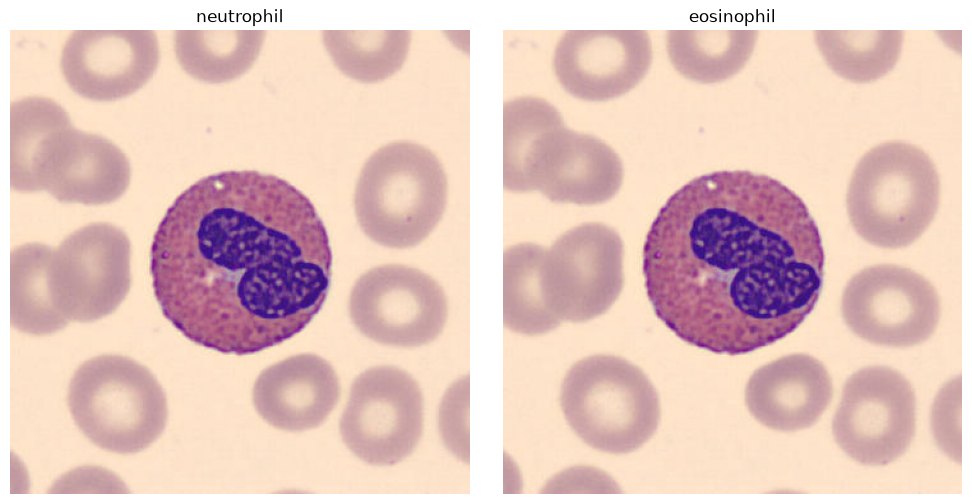

In [ ]:
# Display the pair that appears under two different class labels.
conflicting_paths = [
    DATA_DIR / "neutrophil" / "BNE_191112.jpg",
    DATA_DIR / "eosinophil" / "EO_225902.jpg"
]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, image_path in zip(axes, conflicting_paths):
    with Image.open(image_path) as image:
        ax.imshow(image)

    ax.set_title(image_path.parent.name.capitalize())
    ax.axis("off")

plt.tight_layout()
plt.show()

Visual inspection makes the image look more consistent with an eosinophil than a neutrophil, but this is not enough to establish the correct label with certainty. I therefore treat it as a **suspected annotation inconsistency**, rather than claiming a confirmed labelling error.

To avoid choosing a label without expert validation, both copies of this conflicting image will be excluded from the modelling inventory.

In [ ]:
print("Images in inventory:", len(df))
print("Images inspected for color mode:", len(mode_df))
print("Unique file paths:", df["path"].nunique())

missing_paths = [path for path in df["path"] if not Path(path).exists()]
print("Missing files:", len(missing_paths))

Images in inventory: 17092
Images inspected for color mode: 17092
Unique paths: 17092
Missing files: 0
[]


### Dataset inspection summary

- **17,092** image files in the inventory.
- **8** cell classes.
- All inspected files are RGB JPEG images.
- Most images are 360 × 363 pixels.
- No corrupted images were detected.
- 17 exact-duplicate groups were found, including one cross-class pair that may reflect an annotation inconsistency.

The next step is to remove redundant copies and exclude the conflicting pair before splitting the data.

## 6. Create a cleaned inventory

For duplicate pairs with the same label, I keep one copy and exclude the redundant copy. For the cross-class duplicate, I exclude both copies because the correct label has not been independently verified.

The cleaning is based on the SHA-256 hashes calculated above. This keeps the duplicate detection and cleaning steps consistent.

In [ ]:
df["image_hash"] = df["path"].apply(
    lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
)

keep_indices = []
excluded_indices = []

for _, group in df.groupby("image_hash"):
    if group["class"].nunique() > 1:
        # The same image has conflicting labels: exclude every copy.
        excluded_indices.extend(group.index)
    else:
        # Keep one representative and remove redundant copies.
        keep_indices.append(group.index[0])
        excluded_indices.extend(group.index[1:])

cleaned_df = df.loc[keep_indices].drop(columns=["image_hash"]).copy()

print("Original images:", len(df))
print("Cleaned images:", len(cleaned_df))
print("Excluded images:", len(excluded_indices))
print("\nCleaned class distribution:")
print(cleaned_df["class"].value_counts().sort_index())

Original images: 17092
Cleaned images: 17074
Excluded images: 18

Cleaned class distribution:
class
neutrophil      3328
eosinophil      3110
ig              2892
platelet        2348
erythroblast    1551
monocyte        1419
lymphocyte      1214
basophil        1212
Name: count, dtype: int64


A total of **18 files are excluded**:
- 16 redundant copies from the 16 same-class duplicate pairs.
- Both copies of the one cross-class duplicate pair.

This leaves **17,074 images** in the cleaned inventory (99.89% of the original inventory).

## 7. Examine class imbalance

The number of examples is not the same for every class. I calculate the count and percentage for each class and visualise the distribution.

The imbalance ratio is the number of examples in the largest class divided by the number in the smallest class.

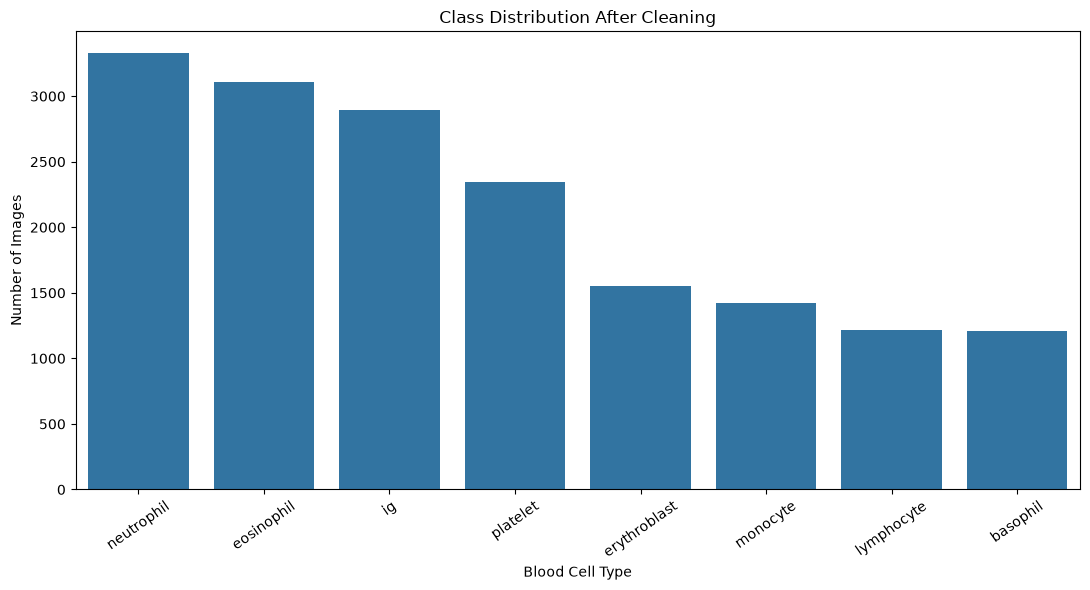

In [ ]:
class_counts = cleaned_df["class"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Class distribution after duplicate removal")
plt.xlabel("Blood cell class")
plt.ylabel("Number of images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### What the distribution tells us

The largest class is **neutrophil** (3,328 images), while the smallest is **basophil** (1,212 images). The imbalance ratio is approximately **2.75:1**.

This is a moderate class imbalance. A model may perform well on the more frequent classes while struggling with less represented ones, so overall accuracy alone will not be enough to assess performance.

For model evaluation, I will also look at:
- **Precision:** of the images predicted as a class, how many were correct?
- **Recall:** of the images that truly belong to a class, how many did the model identify?
- **F1-score:** a balance between precision and recall.
- **Macro F1:** calculates F1 for each class and gives each class equal weight.
- **Confusion matrix:** shows which classes are being confused with one another.

I will preserve all classes for now. Stratified splitting and per-class metrics will help account for the imbalance; class weighting or other techniques can be considered later if the results justify them.

In [ ]:
class_summary = pd.DataFrame({
    "count": cleaned_df["class"].value_counts(),
    "percentage": cleaned_df["class"].value_counts(normalize=True) * 100
})

class_summary["percentage"] = class_summary["percentage"].round(2)
print(class_summary.sort_values("count", ascending=False))

imbalance_ratio = (
    cleaned_df["class"].value_counts().max()
    / cleaned_df["class"].value_counts().min()
)

print(f"\nImbalance ratio: {imbalance_ratio:.2f}:1")

              count  percentage
class                          
neutrophil     3328       19.49
eosinophil     3110       18.21
ig             2892       16.94
platelet       2348       13.75
erythroblast   1551        9.08
monocyte       1419        8.31
lymphocyte     1214        7.11
basophil       1212        7.10

Imbalance ratio: 2.75:1


## 8. Create training, validation and test sets

Before training, I split the cleaned inventory into three independent sets:

- **Training set (70%):** used to fit the model.
- **Validation set (15%):** used to compare models and tune settings.
- **Test set (15%):** held back for the final evaluation.

I use stratified splitting so that each set keeps approximately the same class proportions as the full cleaned dataset. The fixed `random_state` makes the split reproducible.

The test set should not be used to make modelling decisions. It is reserved for the final comparison once model development is complete.

In [ ]:
from sklearn.model_selection import train_test_split

# First, reserve 30% of the data for validation and testing.
train_df, remaining_df = train_test_split(
    cleaned_df,
    test_size=0.30,
    stratify=cleaned_df["class"],
    random_state=42
)

# Split the remaining 30% equally into validation and test sets.
val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df["class"],
    random_state=42
)

print(f"Training images:   {len(train_df):,}")
print(f"Validation images: {len(val_df):,}")
print(f"Test images:       {len(test_df):,}")

Training images: 11951
Validation images: 2561
Testing images: 2562


In [ ]:
split_summary = pd.DataFrame({
    "Train (%)": train_df["class"].value_counts(normalize=True) * 100,
    "Validation (%)": val_df["class"].value_counts(normalize=True) * 100,
    "Test (%)": test_df["class"].value_counts(normalize=True) * 100
})

print(split_summary.sort_index().round(2))

              Train (%)  Validation (%)  Test (%)
class                                            
basophil           7.10            7.11      7.10
eosinophil        18.22           18.20     18.23
erythroblast       9.09            9.10      9.06
ig                16.94           16.95     16.94
lymphocyte         7.11            7.11      7.10
monocyte           8.31            8.32      8.31
neutrophil        19.49           19.48     19.52
platelet          13.76           13.74     13.74


The class percentages are very similar across the three sets, which indicates that stratification has preserved the class distribution as intended.

In [ ]:
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(PROCESSED_DIR / "train.csv", index=False)
val_df.to_csv(PROCESSED_DIR / "validation.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test.csv", index=False)
cleaned_df.to_csv(PROCESSED_DIR / "cleaned_inventory.csv", index=False)

print("Saved processed files to:", PROCESSED_DIR.resolve())
print(" - train.csv")
print(" - validation.csv")
print(" - test.csv")
print(" - cleaned_inventory.csv")

## 9. Wrap-up and next steps

This notebook produced a cleaned and stratified dataset ready for modelling.

| Output | Purpose |
|---|---|
| `cleaned_inventory.csv` | Full cleaned image inventory |
| `train.csv` | Training image paths and labels |
| `validation.csv` | Validation image paths and labels |
| `test.csv` | Held-out test image paths and labels |

In the next notebook, I will prepare the images for model input. After that, I will establish a classical machine-learning baseline using **HOG features and an SVM classifier**, then compare it with a **convolutional neural network (CNN)**.

The main decisions made here — especially duplicate removal, the treatment of the conflicting label pair and the stratified split — should remain documented because they affect how the later model results are interpreted.